# Erosión post-incendio en la cuenca del río Reloca (RUSLE)

**Pregunta:** ¿La pérdida de suelo estimada en la cuenca del río Reloca fue mayor en 2018 que en 2026 como consecuencia del incendio Las Máquinas (enero 2017)?

**Hipótesis:** Un año después del incendio (2018), la pérdida de suelo estimada por RUSLE en las zonas quemadas fue considerablemente mayor que en 2026, por la menor cobertura vegetal (mayor factor C). En las zonas no quemadas la pérdida se mantuvo similar entre ambos años, por lo que la diferencia entre 2018 y 2026 se concentra en lo quemado y es atribuible al incendio.

**Diseño:** $A_{año} = A_{potencial} \times C_{año}$, con $P = 1$

- $A_{potencial}$ es la capa de CIREN ($R \cdot K \cdot LS$, con $C = P = 1$). R, K y LS quedan fijos: en RUSLE representan un año promedio y no cambian entre 2018 y 2026.
- Solo cambia **C**, calculado con Landsat en el verano 2017-18 y en el verano 2025-26.
- El efecto del incendio se mide como **(cambio en lo quemado) − (cambio en lo no quemado)**. Restar lo no quemado descuenta lo que habría cambiado de todas formas.

**Flujo del notebook**
1. Punto de partida: pérdida potencial de CIREN (Etapa 1)
2. Zona quemada y severidad del incendio
3. Factor C en 2018 y 2026
4. De píxeles a celdas de 1 ha
5. Pérdida de suelo 2018 y 2026 (Etapa 2)
6. Comparación (Etapa 3)
7. Sensibilidad a la lluvia (R de cada año)
8. Contraste con los estados erosivos de CIREN
9. Exportar resultados

In [1]:
# =============================================================================
# Erosión post-incendio (Las Máquinas, 2017) en la cuenca del río Reloca, Región del Maule
# Modelo RUSLE: A = R·K·LS·C·P  →  A_año = A_potencial (CIREN) × C_año, con P = 1
#
# FUENTES DE DATOS
# -----------------------------------------------------------------------------
# Capas vectoriales de CIREN (WFS; convertidas a ee.FeatureCollection con geemap):
#   r07_066_rep_1ha         Pérdida de suelo potencial (R·K·LS, C = P = 1), celdas de 1 ha.
#                           CIREN, Inventario de Erosión de Suelos, versión 2024.
#                           https://inventarioerosion.ciren.cl
#   r07_066_grados_erosion  Estados erosivos actuales, 1:10.000. CIREN, versión 2024.
#
# ee.ImageCollection:
#   LANDSAT/LC08/C02/T1_L2  Landsat 8, Colección 2, Nivel 2 (reflectancia de superficie, 30 m). USGS.
#   LANDSAT/LC09/C02/T1_L2  Landsat 9, Colección 2, Nivel 2 (30 m). USGS.
#                           Ambas se usan para el factor C (NDVI) y la severidad del incendio (dNBR).
#   MODIS/061/MCD64A1       Área quemada mensual, 500 m (Giglio et al., 2018). Contraste del área quemada.
#   UCSB-CHG/CHIRPS/DAILY   Precipitación diaria, ~5,5 km (Funk et al., 2015). Solo para la sensibilidad a R.
# =============================================================================

import ee                                  # Google Earth Engine: imágenes satelitales y cálculos en el servidor
import geemap                              # mapas interactivos y conversión geopandas → Earth Engine
import geopandas as gpd                    # capas vectoriales de CIREN (celdas de 1 ha, estados erosivos)
import numpy as np                         # arreglos de los rásters descargados desde GEE
import pandas as pd                        # tablas de resultados
import matplotlib.pyplot as plt            # paleta de colores y mapas estáticos
from matplotlib.colors import to_hex       # GEE pide los colores en formato hex ('#rrggbb')
from matplotlib.patches import Patch       # cuadros de color para la leyenda de los mapas estáticos

**Pasos para activar su cuenta de Google con un proyecto GEE**

1. Crear cuenta de Google (si no tienen una).
2. Ir a https://earthengine.google.com/signup/ e iniciar sesión con su cuenta de Google. Completar el formulario de registro seleccionando 'Uso no comercial / académico'.
3. Crear un proyecto en Google Cloud Console. Ir a https://console.cloud.google.com/projectcreate, ponerle un nombre al proyecto (ej. 'clase-erosion-nombre') y anotar ese Project ID.
4. Habilitar la API de Earth Engine en el proyecto. Con el proyecto creado y seleccionado, ir a https://console.cloud.google.com/apis/library/earthengine.googleapis.com y hacer clic en 'Habilitar'.
5. Registrar el proyecto para uso con Earth Engine. Ir a https://console.cloud.google.com/earth-engine/configuration y seguir los pasos, indicando que es para investigación/uso académico no comercial.

In [2]:
GEE_PROJECT = 'cuenca-reloca'   # Elegimos el Project ID de Google Cloud registrado en Earth Engine, yo elegi la cuenca de Reloca
#iniciamos sesion en GEE
print("Autenticando...")
ee.Authenticate()

print(f"Inicializando proyecto: {GEE_PROJECT}...")
try:
    ee.Initialize(project=GEE_PROJECT)   # todas las operaciones de GEE se cobran/registran en este proyecto
    print("✓ Google Earth Engine inicializado correctamente!")

    info = ee.Number(1).getInfo()        # pedido mínimo al servidor: si responde, la conexión funciona
    print("✓ Conexión verificada.")

# Mensajes según el tipo de error, para saber qué corregir sin leer el error completo
except ee.EEException as e:
    print(f"\n✗ Falló la inicialización: {e}")
    if "not registered" in str(e):       # el proyecto existe pero no está habilitado para Earth Engine
        print(f"\nACCIÓN REQUERIDA: El proyecto '{GEE_PROJECT}' no está registrado en Earth Engine.")
        print(f"1. Regístralo aquí: https://console.cloud.google.com/earth-engine/configuration?project={GEE_PROJECT}")
        print("2. O actualiza la variable GEE_PROJECT con un Project ID válido.")
    elif "permission" in str(e).lower(): # la cuenta no tiene acceso a ese proyecto
        print(f"\nACCIÓN REQUERIDA: Puede que no tengas permisos para el proyecto '{GEE_PROJECT}'.")
        print("Revisa la configuración de IAM en Google Cloud Console.")
except Exception as e:                   # cualquier otro problema (internet, librería, etc.)
    print(f"\n✗ Ocurrió un error inesperado: {e}")

Autenticando...
Inicializando proyecto: cuenca-reloca...
✓ Google Earth Engine inicializado correctamente!
✓ Conexión verificada.


## 1. Punto de partida: pérdida potencial de CIREN (Etapa 1)

La capa potencial de CIREN calcula $A = R \cdot K \cdot LS$ con **C = P = 1**, es decir, supone el suelo **desnudo y sin prácticas de conservación**. Es un escenario hipotético que mide la susceptibilidad del terreno (lluvia, suelo y relieve), **no** la erosión que ocurre hoy. En este trabajo es la base del modelo: a cada celda se le aplica el C de cada año.

In [3]:
# Capa CIREN: región 07 (Maule), cuenca 066, "rep" = pérdida de suelo POTENCIAL
# (R·K·LS calculados por CIREN, con C = P = 1), en celdas de 1 ha.
# Es la base del modelo: a esta capa se le aplica el C de cada año.
CAPA = "r07_066_rep_1ha"

# Consulta WFS al geoserver de CIREN. Se pide en EPSG:32719 (UTM 19S, en metros)
# para poder calcular áreas en m² y alinear los píxeles de Landsat con las celdas.
url = ("https://inventarioerosion.ciren.cl/geoserver/ows?service=WFS&version=1.0.0"
       f"&request=GetFeature&typename=geonode%3A{CAPA}&outputFormat=json"
       "&srsName=EPSG%3A32719")

gdf = gpd.read_file(url).reset_index(drop=True)   # una fila por celda de 1 ha; índice 0..n para unir resultados después

# COD_RANGO se pasa a entero para ordenar las clases de menor a mayor erosión
# y para poder compararlo con el código 999 ("No suelos") más adelante.
gdf["COD_RANGO"] = gdf["COD_RANGO"].astype(int)

# Pérdida potencial de cada celda (ton/ha/año), que se multiplicará por C.
# errors="coerce" deja vacío (NaN) cualquier valor no numérico, por ejemplo en "No suelos".
gdf["RUSLE"] = pd.to_numeric(gdf["RUSLE"], errors="coerce")

# Lista las clases presentes en la cuenca, sin repetir, para ver qué rangos
# de pérdida (ton/ha/año) usa CIREN antes de armar la leyenda.
print(gdf[["COD_RANGO", "RANGO", "CLASEROS"]].drop_duplicates().sort_values("COD_RANGO"))

     COD_RANGO      RANGO          CLASEROS
122          1      0 - 5              NULA
137          2     5 - 10          MUY LEVE
10           3    10 - 25              LEVE
65           4    25 - 50   MODERADA - LEVE
36           5   50 - 100  MODERADA - GRAVE
209          6  100 - 200             GRAVE
208          7      > 200         MUY GRAVE
0          999  NO SUELOS         NO SUELOS


In [4]:
# Etiqueta legible por clase, ej. "5-10 (Moderada)". El código 999 de CIREN
# no es una clase de erosión sino áreas sin suelo, por eso lleva otro texto.
gdf["ETIQUETA"] = gdf.apply(
    lambda r: "No suelos" if r.COD_RANGO == 999 else f"{r.RANGO} ({r.CLASEROS})", axis=1)

# Área de cada polígono en hectáreas. Como la capa viene en UTM (metros),
# .area entrega m² y se divide por 10 000 para pasar a ha.
gdf["AREA_CALC_HA"] = gdf.geometry.area / 10_000

# Suma las hectáreas de todas las celdas de una misma clase para saber
# cuánta superficie de la cuenca cae en cada rango de erosión.
tabla = (gdf.groupby(["COD_RANGO", "ETIQUETA"])["AREA_CALC_HA"].sum()
            .reset_index().sort_values("COD_RANGO"))

# Proporción de la cuenca en cada clase, para comparar después con la
# distribución que entregue el modelo RUSLE.
tabla["PORCENTAJE"] = 100 * tabla["AREA_CALC_HA"] / tabla["AREA_CALC_HA"].sum()
print(tabla.round(2).to_string(index=False))

# Guarda la capa (con ETIQUETA y AREA_CALC_HA) en GeoPackage para revisarla
# o hacer el mapa final en QGIS.
gdf.to_file("reloca_potencial.gpkg", layer="perdida_potencial", driver="GPKG")

 COD_RANGO                    ETIQUETA  AREA_CALC_HA  PORCENTAJE
         1                0 - 5 (NULA)       4922.41       11.45
         2           5 - 10 (MUY LEVE)       1165.05        2.71
         3              10 - 25 (LEVE)       2535.54        5.90
         4   25 - 50 (MODERADA - LEVE)       3951.16        9.19
         5 50 - 100 (MODERADA - GRAVE)       7299.76       16.98
         6           100 - 200 (GRAVE)      11853.56       27.57
         7           > 200 (MUY GRAVE)      10229.26       23.80
       999                   No suelos       1031.39        2.40


In [5]:
# 1. Etiquetas de la leyenda, de menor a mayor erosión
clases = gdf[["COD_RANGO", "RANGO", "CLASEROS"]].drop_duplicates().sort_values("COD_RANGO")
etiquetas = {
    r.COD_RANGO: "No suelos" if r.COD_RANGO == 999 else f"{r.RANGO} ({r.CLASEROS})"
    for r in clases.itertuples()
}

# 2. Colores
codigos_suelo = [k for k in etiquetas if k != 999]       # 999 fuera de la escala de erosión
cmap = plt.get_cmap("RdYlGn_r", len(codigos_suelo))      # verde = poca erosión, rojo = mucha; un color por clase
colores = {k: to_hex(cmap(i)) for i, k in enumerate(codigos_suelo)}
colores[999] = "#bdbdbd"                                 # gris: sin suelo

# 3. Preparar la capa para GEE (en UTM, para que buffer y simplify vayan en metros)
gdf_d = gdf[["COD_RANGO", "geometry"]].dissolve(by="COD_RANGO").reset_index()   # miles de celdas → 1 polígono por clase, si no GEE no lo procesa
gdf_d["geometry"] = gdf_d.geometry.buffer(0)                                    # repara geometrías inválidas del dissolve
gdf_d["geometry"] = gdf_d.geometry.simplify(5, preserve_topology=True)          # 5 m << celda de 100 m: no cambia el mapa y pesa menos
gdf_d_wgs = gdf_d.to_crs(4326)                                                  # GEE recibe coordenadas en WGS84

tamano_mb = len(gdf_d_wgs.to_json()) / 1e6               # GEE rechaza solicitudes muy pesadas (~10 MB)
print(f"Tamaño aprox.: {tamano_mb:.1f} MB")
if tamano_mb > 10:
    raise ValueError("Sigue pesando más de 10 MB: sube la tolerancia de simplify (p. ej. 15 m).")

fc = geemap.geopandas_to_ee(gdf_d_wgs)                   # clases en GEE, solo para dibujar

cuenca = gdf_d_wgs[["geometry"]].dissolve()              # solo el contorno de la cuenca
area_de_interes = geemap.geopandas_to_ee(cuenca)         # límite para recortar R, K, L, S, C y P

# 4. Estilo por clase
colores_ee = ee.Dictionary({str(k): v for k, v in colores.items()})   # ee.Dictionary solo acepta claves de texto

def estilo(f):
    col = colores_ee.get(ee.Number(f.get("COD_RANGO")).format("%d"))  # "3" y no "3.0", para calzar con las claves
    return f.set("style", {"color": col, "fillColor": col, "width": 0})   # sin borde entre polígonos

# 5. Mapa
xmin, ymin, xmax, ymax = gdf_d_wgs.total_bounds          # centro calculado localmente, sin consultar a GEE
Map = geemap.Map(basemap="SATELLITE")                    # fondo satelital para ubicar la cuenca
Map.set_center((xmin + xmax) / 2, (ymin + ymax) / 2, 12) # zoom 12: cuenca completa
Map.addLayer(fc.map(estilo).style(styleProperty="style"), {}, "Pérdida potencial (C=P=1)")   # el color va en cada polígono, por eso {}
Map.add_legend(
    title="Pérdida potencial (ton/ha/año)",
    legend_dict={etiquetas[k]: colores[k] for k in etiquetas},
)
Map

Tamaño aprox.: 4.5 MB


Map(center=[np.float64(-35.6891540293703), np.float64(-72.37196084747961)], controls=(WidgetControl(options=['…

In [6]:
# Mapa de trabajo donde se irán sumando la zona quemada, la severidad y C de cada año
mapa_simple = geemap.Map(basemap="SATELLITE")   # fondo satelital; el fondo por defecto (OpenStreetMap)
mapa_simple.centerObject(area_de_interes, zoom=12)
mapa_simple.addLayer(area_de_interes, {'color': 'black'}, 'Área de interés')   # contorno de referencia
mapa_simple

Map(center=[-35.67878001827786, -72.35932430894306], controls=(WidgetControl(options=['position', 'transparent…

## 2. El incendio Las Máquinas: zona quemada y severidad

El incendio partió el 20 de enero de 2017 y quemó 183 946 ha en Empedrado, Constitución y Cauquenes.

- **MODIS MCD64A1 (500 m):** producto oficial de área quemada. Se usa como contraste.
- **dNBR con Landsat (30 m):** compara el *Normalized Burn Ratio* antes y después del incendio. Es más detallado y además entrega la **severidad**. Es el que se usa en el análisis.

Clases de severidad según Key & Benson (2006): no quemado (dNBR < 0,10), baja (0,10–0,27), moderada (0,27–0,66) y alta (≥ 0,66). Las dos clases moderadas de los autores se juntan en una.

In [7]:
# Contraste: área quemada según MODIS (500 m). El análisis usa el dNBR de Landsat (30 m, celda siguiente).
# MODIS MCD64A1 (500 m): área quemada mensual; BurnDate > 0 indica el día del año en que se quemó el píxel
quemado = (ee.ImageCollection('MODIS/061/MCD64A1')
           .filterDate('2017-01-01', '2017-03-01')   # Las Máquinas partió el 20-ene-2017 y se controló a inicios de febrero
           .select('BurnDate')
           .max()                                    # un píxel quemado en enero o febrero queda con valor > 0
           .gt(0)                                    # 1 = quemado, 0 = no quemado
           .clip(area_de_interes))

# Suma solo los píxeles quemados para obtener la superficie afectada dentro de la cuenca
sup = (ee.Image.pixelArea().divide(1e4)               # área de cada píxel en ha
       .updateMask(quemado)                           # deja solo los píxeles quemados
       .reduceRegion(reducer=ee.Reducer.sum(), geometry=area_de_interes.geometry(),
                     scale=500, maxPixels=1e9, bestEffort=True).getInfo())

print(f"Superficie quemada: {sup['area']:,.0f} ha ({100*sup['area']/42988.1:.1f} % de la cuenca)")   # 42 988,1 ha según CIREN

mapa_simple.addLayer(quemado.selfMask(), {'palette': ['black']}, 'Área quemada 2017 (MODIS)')
mapa_simple

Superficie quemada: 23,987 ha (55.8 % de la cuenca)


Map(center=[-35.67878001827786, -72.35932430894306], controls=(WidgetControl(options=['position', 'transparent…

In [8]:
# --- Funciones para armar compuestos Landsat sin nubes (se usan para el dNBR y para C) ---

def enmascarar_nubes(img):
    qa = img.select('QA_PIXEL')
    # Bits 3 (nube) y 4 (sombra de nube) de QA_PIXEL: una nube o su sombra alterarían el NDVI y el NBR
    despejado = qa.bitwiseAnd(1 << 3).eq(0).And(qa.bitwiseAnd(1 << 4).eq(0))
    return img.updateMask(despejado)

def reflectancia(img):
    # Factores de escala de la Colección 2, Nivel 2: pasan los valores enteros a reflectancia (0 a 1)
    return img.select('SR_B.').multiply(0.0000275).add(-0.2)

def compuesto_landsat(inicio, fin):
    # Landsat 8 y 9 juntos: sus sensores (OLI y OLI-2) son casi idénticos y así hay más escenas sin nubes.
    # Landsat 9 opera desde fines de 2021, así que en 2017-2018 solo aporta Landsat 8.
    col = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
           .merge(ee.ImageCollection('LANDSAT/LC09/C02/T1_L2'))
           .filterBounds(area_de_interes)
           .filterDate(inicio, fin)
           .filter(ee.Filter.lt('CLOUD_COVER', 50))   # descarta escenas muy nubladas; las nubes que quedan se enmascaran
           .map(enmascarar_nubes)
           .map(reflectancia))
    print(f"  Escenas Landsat entre {inicio} y {fin}: {col.size().getInfo()}")
    # Mediana píxel a píxel: elimina restos de nubes y valores extremos de una sola fecha
    return col.median().clip(area_de_interes)

In [9]:
# --- Severidad del incendio con dNBR (Key & Benson, 2006) ---
# NBR = (NIR − SWIR2) / (NIR + SWIR2): alto en vegetación sana, bajo en suelo quemado.
# dNBR = NBR antes − NBR después: cuanto mayor, más severo fue el incendio.

print("Compuestos para el dNBR:")
pre = compuesto_landsat('2016-12-01', '2017-01-20')    # verano previo, hasta el día en que partió el incendio (20-ene-2017)
post = compuesto_landsat('2017-02-10', '2017-04-01')   # recién controlado el fuego, antes del rebrote y de las lluvias de otoño

nbr_pre = pre.normalizedDifference(['SR_B5', 'SR_B7'])    # B5 = infrarrojo cercano, B7 = infrarrojo de onda corta 2
nbr_post = post.normalizedDifference(['SR_B5', 'SR_B7'])
dnbr = nbr_pre.subtract(nbr_post).rename('dNBR')

# Clase de severidad: cada umbral superado suma 1 → 0 = no quemado, 1 = baja, 2 = moderada, 3 = alta
severidad = dnbr.gte(0.10).add(dnbr.gte(0.27)).add(dnbr.gte(0.66)).rename('severidad')

# Superficie de cada clase de severidad dentro de la cuenca (banda 0 = área en ha, banda 1 = clase)
sup_sev = (ee.Image.pixelArea().divide(1e4).addBands(severidad)
           .reduceRegion(reducer=ee.Reducer.sum().group(groupField=1, groupName='clase'),
                         geometry=area_de_interes.geometry(), scale=30,   # 30 m: resolución nativa de Landsat
                         maxPixels=1e9, bestEffort=True)
           .getInfo())

NOMBRES_SEV = {0: 'No quemado', 1: 'Baja', 2: 'Moderada', 3: 'Alta'}
total_sev = sum(g['sum'] for g in sup_sev['groups'])
print(f"\n{'Severidad':<12}{'ha':>10}{'%':>8}")
for g in sup_sev['groups']:
    print(f"{NOMBRES_SEV[int(g['clase'])]:<12}{g['sum']:>10,.0f}{100 * g['sum'] / total_sev:>7.1f}%")

# Comparación con MODIS: ambos productos deberían dar una superficie quemada del mismo orden
quemado_dnbr = sum(g['sum'] for g in sup_sev['groups'] if g['clase'] >= 1)
print(f"\nQuemado según dNBR: {quemado_dnbr:,.0f} ha   |   según MODIS: {sup['area']:,.0f} ha")

mapa_simple.addLayer(severidad.selfMask(), {'min': 1, 'max': 3, 'palette': ['yellow', 'orange', 'darkred']},
                     'Severidad del incendio (dNBR)')

mapa_simple

Compuestos para el dNBR:
  Escenas Landsat entre 2016-12-01 y 2017-01-20: 5
  Escenas Landsat entre 2017-02-10 y 2017-04-01: 5

Severidad           ha       %
No quemado      15,320   35.7%
Baja             9,945   23.2%
Moderada        11,483   26.8%
Alta             6,122   14.3%

Quemado según dNBR: 27,551 ha   |   según MODIS: 23,987 ha


Map(center=[-35.67878001827786, -72.35932430894306], controls=(WidgetControl(options=['position', 'transparent…

In [21]:
# --- Mapa de severidad para el informe  ---
mapa_sev = geemap.Map(basemap="SATELLITE")                    # fondo satelital para ubicar la cuenca
mapa_sev.centerObject(area_de_interes, zoom=12)

# Solo el contorno de la cuenca (relleno transparente), para que no tape la imagen
mapa_sev.addLayer(area_de_interes.style(color='white', fillColor='00000000', width=2), {}, 'Cuenca del río Reloca')

# Severidad: solo píxeles quemados (selfMask oculta el 0 = no quemado)
mapa_sev.addLayer(severidad.selfMask(), {'min': 1, 'max': 3, 'palette': ['yellow', 'orange', 'darkred']},
                  'Severidad del incendio (dNBR)')

# Leyenda con los umbrales de Key & Benson (2006)
mapa_sev.add_legend(title="Severidad del incendio (dNBR)",
                    legend_dict={"Baja (0,10–0,27)": "#ffff00",
                                 "Moderada (0,27–0,66)": "#ffa500",
                                 "Alta (≥ 0,66)": "#8b0000"})
mapa_sev

Map(center=[-35.6787800182776, -72.35932430894344], controls=(WidgetControl(options=['position', 'transparent_…

## 3. Factor C en 2018 y 2026

C se calcula a partir del NDVI de un compuesto Landsat de **verano** en ambos años: **2017-18** (el primer verano después del incendio) y **2025-26** (el más reciente). Usar la misma estación evita que la diferencia se deba a la fenología (pasto seco frente a pasto verde) y no a la recuperación.

**Fórmula de C.** Se usa la de Van der Knijff et al. (2000):

$$C = \exp\left(-\alpha \frac{NDVI}{\beta - NDVI}\right), \quad \alpha = 2, \ \beta = 1$$

La fórmula de De Jong (1994), $C = 0{,}431 - 0{,}805 \cdot NDVI$, da **C = 0** cuando el NDVI supera 0,535. En la versión anterior de este notebook (2023-24) el NDVI medio de la cuenca era 0,67 y el C medio quedó en **0,019**: gran parte de la cuenca tendría pérdida de suelo cero, lo que no es físicamente realista, y además se esconderían las diferencias entre años en las zonas con vegetación. La fórmula exponencial baja de forma gradual y nunca llega a cero. Para comparar, se puede cambiar `METODO_C = 'de_jong'`.

In [10]:
# --- Factor C para 2018 y 2026 ---
METODO_C = 'van_der_knijff'   # 'van_der_knijff' (recomendado) o 'de_jong' (para comparar)

def factor_c(ndvi):
    if METODO_C == 'de_jong':
        # De Jong (1994): C = 0,431 − 0,805·NDVI; llega a 0 cuando NDVI > 0,535
        c = ee.Image(0.431).subtract(ndvi.multiply(0.805))
    else:
        # Van der Knijff et al. (2000): C = exp(−2·NDVI / (1 − NDVI)); baja gradualmente y nunca llega a 0
        c = ndvi.multiply(-2).divide(ee.Image(1).subtract(ndvi)).exp()
    return c.clamp(0, 1)   # C es una proporción: fuera de [0, 1] no tiene sentido (p. ej. agua, con NDVI < 0)

print("Compuestos para C:")
comp_2018 = compuesto_landsat('2017-12-01', '2018-04-01')   # verano 2017-18: primer verano después del incendio
comp_2026 = compuesto_landsat('2025-12-01', '2026-04-01')   # verano 2025-26: el más reciente, misma estación que 2018

ndvi_2018 = comp_2018.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI_2018')   # B5 = infrarrojo cercano, B4 = rojo
ndvi_2026 = comp_2026.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI_2026')
C_2018 = factor_c(ndvi_2018).rename('C_2018')
C_2026 = factor_c(ndvi_2026).rename('C_2026')

# Promedios en toda la cuenca, como primera revisión antes del análisis por zona
est = (ee.Image.cat([ndvi_2018, ndvi_2026, C_2018, C_2026])
       .reduceRegion(reducer=ee.Reducer.mean(), geometry=area_de_interes.geometry(),
                     scale=30, maxPixels=1e9, bestEffort=True)
       .getInfo())
print("Promedios en la cuenca:", {k: round(v, 3) for k, v in est.items()})

# Misma escala fija en ambos años, para que los colores sean comparables entre mapas
viz_C = {'min': 0, 'max': 0.5, 'palette': ['darkgreen', 'yellow', 'orange', 'brown']}
mapa_simple.addLayer(C_2018, viz_C, 'C 2018')
mapa_simple.addLayer(C_2026, viz_C, 'C 2026')
mapa_simple

Compuestos para C:
  Escenas Landsat entre 2017-12-01 y 2018-04-01: 12
  Escenas Landsat entre 2025-12-01 y 2026-04-01: 26
Promedios en la cuenca: {'C_2018': 0.195, 'C_2026': 0.076, 'NDVI_2018': 0.52, 'NDVI_2026': 0.68}


Map(center=[-35.67878001827786, -72.35932430894306], controls=(WidgetControl(options=['position', 'transparent…

## 4. De píxeles de 30 m a celdas de 1 ha

La pérdida potencial de CIREN viene en celdas de 1 ha (100 × 100 m), y C y dNBR están en píxeles de 30 m. Para combinarlos:

1. Se descargan C, NDVI y dNBR desde GEE en una grilla de 30 m en el mismo sistema de coordenadas de CIREN (UTM 19S).
2. Se promedian los píxeles que caen dentro de cada celda (unos 11 por celda).

Así cada celda de CIREN queda con su potencial, su C de 2018, su C de 2026 y su dNBR.

In [11]:
# --- Descargar C, NDVI y dNBR en una grilla de 30 m alineada con la capa de CIREN ---
ESCALA = 30            # m: resolución nativa de Landsat
CRS = 'EPSG:32719'     # UTM 19S, el mismo sistema de la capa de CIREN, para que píxeles y celdas calcen

xmin, ymin, xmax, ymax = gdf.total_bounds                 # extensión de la cuenca en metros
x0 = np.floor(xmin / ESCALA) * ESCALA                     # esquina superior izquierda de la grilla, en múltiplos de 30 m
y0 = np.ceil(ymax / ESCALA) * ESCALA
ancho = int(np.ceil((xmax - x0) / ESCALA))                # columnas y filas necesarias para cubrir la cuenca
alto = int(np.ceil((y0 - ymin) / ESCALA))
print(f"Grilla: {ancho} × {alto} píxeles de {ESCALA} m")

def descargar(img):
    nombre = img.bandNames().getInfo()[0]
    arr = ee.data.computePixels({
        'expression': img.unmask(-9999).toFloat(),         # -9999 marca píxeles sin dato (fuera de la cuenca o con nubes)
        'fileFormat': 'NUMPY_NDARRAY',
        'grid': {'dimensions': {'width': ancho, 'height': alto},
                 'affineTransform': {'scaleX': ESCALA, 'shearX': 0, 'translateX': float(x0),
                                     'shearY': 0, 'scaleY': -ESCALA, 'translateY': float(y0)},
                 'crsCode': CRS},
    })
    arr = arr[nombre].astype(float)
    arr[arr == -9999] = np.nan                            # sin dato → NaN, para que no entre en los promedios
    return arr

rasters = {}
for img in [C_2018, C_2026, ndvi_2018, ndvi_2026, dnbr]:
    nombre = img.bandNames().getInfo()[0]
    print(f"Descargando {nombre}...")
    rasters[nombre] = descargar(img)
print("Listo.")

Grilla: 1558 × 804 píxeles de 30 m
Descargando C_2018...
Descargando C_2026...
Descargando NDVI_2018...
Descargando NDVI_2026...
Descargando dNBR...
Listo.


In [12]:
# --- Promedio de cada variable dentro de cada celda de 1 ha ---
filas, cols = np.indices((alto, ancho))
xc = x0 + (cols + 0.5) * ESCALA      # coordenadas del centro de cada píxel
yc = y0 - (filas + 0.5) * ESCALA
validos = np.any([~np.isnan(a) for a in rasters.values()], axis=0)   # solo píxeles con algún dato (dentro de la cuenca)

pix = gpd.GeoDataFrame({n: a[validos] for n, a in rasters.items()},
                       geometry=gpd.points_from_xy(xc[validos], yc[validos]), crs=gdf.crs)
pix = gpd.sjoin(pix, gdf[["geometry"]], predicate="within", how="inner")   # a qué celda pertenece cada píxel
medias = pix.groupby("index_right")[list(rasters)].mean()                 # promedio por celda (ignora los NaN)

# Celdas muy pequeñas del borde pueden no contener ningún centro de píxel: se usa el píxel de su centroide
cent = gdf.geometry.centroid
j = ((cent.x - x0) // ESCALA).astype(int).clip(0, ancho - 1).to_numpy()
i = ((y0 - cent.y) // ESCALA).astype(int).clip(0, alto - 1).to_numpy()
for n, a in rasters.items():
    gdf[n] = medias[n].reindex(gdf.index)
    faltan = gdf[n].isna().to_numpy()
    gdf.loc[faltan, n] = a[i[faltan], j[faltan]]

print(gdf[list(rasters)].describe().round(3))

          C_2018     C_2026  NDVI_2018  NDVI_2026       dNBR
count  44083.000  44083.000  44083.000  44083.000  44083.000
mean       0.195      0.074      0.520      0.682      0.283
std        0.161      0.111      0.194      0.174      0.292
min        0.000      0.000      0.038      0.065     -0.551
25%        0.033      0.000      0.366      0.551      0.042
50%        0.181      0.013      0.468      0.724      0.204
75%        0.319      0.107      0.666      0.832      0.457
max        0.924      0.871      0.944      0.942      1.204


## 5. Pérdida de suelo 2018 y 2026 (Etapa 2)

$$A_{año} = A_{potencial} \times C_{año} \times P, \quad P = 1$$

- **Qué usaba CIREN:** $R$ con datos de la DGA y la DMC, $K$ de su cartografía de suelos del Maule y muestreo 2020, $LS$ de LiDAR y ALOS PALSAR, y $C = P = 1$ en la capa potencial.
- **Qué se cambia:** solo **C**, calculado con Landsat para cada año.
- **P = 1:** no hay un catastro de prácticas de conservación para la cuenca, y CIREN también usa P = 1 en su capa de pérdida actual. Al dejarlo fijo, la diferencia entre años se debe solo a la vegetación.
- Las celdas **"No suelos"** (agua, rocas, zonas urbanas) quedan fuera, igual que en CIREN.
- El resultado se clasifica con los **mismos rangos y nombres de CIREN**, para que sea comparable con su capa.

In [13]:
# --- Pérdida de suelo de cada año: A = A_potencial × C, con P = 1 ---
suelo = gdf["COD_RANGO"] != 999                             # "No suelos" no se erosiona en RUSLE
gdf["A_2018"] = (gdf["RUSLE"] * gdf["C_2018"]).where(suelo)   # ton/ha/año con la vegetación de 2018
gdf["A_2026"] = (gdf["RUSLE"] * gdf["C_2026"]).where(suelo)   # ton/ha/año con la vegetación de 2026

# Mismos rangos y nombres de CIREN (ton/ha/año), para que las clases sean comparables con su capa
CORTES = [0, 5, 10, 25, 50, 100, 200, np.inf]
CLASES = ["NULA", "MUY LEVE", "LEVE", "MODERADA - LEVE", "MODERADA - GRAVE", "GRAVE", "MUY GRAVE"]

def clasificar(a):
    return pd.cut(a, bins=CORTES, labels=CLASES, right=False)   # right=False: el valor 5 cae en "5 - 10", como en CIREN

gdf["CLASE_POT"] = clasificar(gdf["RUSLE"].where(suelo))
gdf["CLASE_2018"] = clasificar(gdf["A_2018"])
gdf["CLASE_2026"] = clasificar(gdf["A_2026"])

# Severidad de cada celda según su dNBR medio (umbrales de Key & Benson, 2006)
gdf["SEVERIDAD"] = pd.cut(gdf["dNBR"], bins=[-np.inf, 0.10, 0.27, 0.66, np.inf],
                          labels=["No quemado", "Baja", "Moderada", "Alta"], right=False)
# Zona quemada = cualquier severidad desde "Baja" (dNBR ≥ 0,10); sin dNBR (nubes) queda vacía
gdf["ZONA"] = np.where(gdf["dNBR"].isna(), None,
                       np.where(gdf["dNBR"] >= 0.10, "Quemado", "No quemado"))

# Celdas que entran a la comparación: con suelo, con A en ambos años y con dNBR
analisis = gdf[suelo & gdf[["A_2018", "A_2026", "dNBR"]].notna().all(axis=1)].copy()
print(f"Celdas analizadas: {len(analisis):,} ({analisis['AREA_CALC_HA'].sum():,.0f} ha)")
print(analisis.groupby("ZONA")["AREA_CALC_HA"].sum().round(0).to_string())

Celdas analizadas: 43,901 (41,957 ha)
ZONA
No quemado    14226.0
Quemado       27730.0


## 6. Comparación (Etapa 3)

Para cada zona se calcula el cambio $\Delta = A_{2018} - A_{2026}$ (positivo = hubo más erosión en 2018).

$$\text{Efecto del incendio} = \Delta_{quemado} - \Delta_{no\ quemado}$$

No se comparan directamente lo quemado y lo no quemado, porque son terrenos distintos (interior frente a costa). Se compara **cuánto cambió cada uno**. Si ambos cambian igual, la diferencia entre años no se debe al incendio.

Tablas:
1. Pérdida media y C medio por zona y por severidad, y efecto del incendio
2. Superficie por clase de CIREN (potencial, 2018 y 2026)
3. Transiciones de clase entre 2018 y 2026
4. Superficie sobre umbrales de tolerancia
5. Cambio por clase de pérdida potencial (dónde se concentra)

In [14]:
# --- Tabla 1: pérdida media por zona y por severidad ---
VARS = ["RUSLE", "C_2018", "C_2026", "A_2018", "A_2026"]

def resumen(df, por):
    # Promedios ponderados por superficie: las celdas del borde de la cuenca miden menos de 1 ha
    w = df["AREA_CALC_HA"]
    g = df.assign(**{f"_{c}": df[c] * w for c in VARS}).groupby(por, observed=True)
    t = pd.DataFrame({"ha": g["AREA_CALC_HA"].sum()})
    for c in VARS:
        t[c] = g[f"_{c}"].sum() / t["ha"]
    t = t.rename(columns={"RUSLE": "A_potencial"})
    t["Δ (2018 − 2026)"] = t["A_2018"] - t["A_2026"]          # positivo = hubo más erosión en 2018
    t["Δ %"] = 100 * t["Δ (2018 − 2026)"] / t["A_2018"]       # cambio relativo a 2018
    return t

t_zona = resumen(analisis, "ZONA")
print("Pérdida media (ton/ha/año) y C medio, por zona:")
print(t_zona.round(3).to_string())

# Efecto atribuible al incendio: cuánto más bajó la erosión en lo quemado que en lo no quemado.
# Restar el cambio de lo no quemado descuenta lo que habría cambiado igual (clima del verano, sensor, etc.).
efecto = t_zona.loc["Quemado", "Δ (2018 − 2026)"] - t_zona.loc["No quemado", "Δ (2018 − 2026)"]
print(f"\nExceso de pérdida en 2018 atribuible al incendio: {efecto:.2f} ton/ha/año")

t_sev = resumen(analisis, "SEVERIDAD")
print("\nPor severidad del incendio:")
print(t_sev.round(3).to_string())

Pérdida media (ton/ha/año) y C medio, por zona:
                  ha  A_potencial  C_2018  C_2026  A_2018  A_2026  Δ (2018 − 2026)     Δ %
ZONA                                                                                      
No quemado  14226.24      100.423   0.082   0.090   4.675   5.978           -1.303 -27.861
Quemado     27730.46      145.945   0.250   0.063  36.108   4.824           31.284  86.641

Exceso de pérdida en 2018 atribuible al incendio: 32.59 ton/ha/año

Por severidad del incendio:
                   ha  A_potencial  C_2018  C_2026  A_2018  A_2026  Δ (2018 − 2026)     Δ %
SEVERIDAD                                                                                  
No quemado  14226.240      100.423   0.082   0.090   4.675   5.978           -1.303 -27.861
Baja        10203.310       86.084   0.209   0.116  16.239   6.362            9.877  60.824
Moderada    11689.207      158.121   0.282   0.042  43.762   4.814           38.947  88.999
Alta         5837.943      226.

In [15]:
# --- Tabla 2: superficie por clase de CIREN en cada zona y escenario ---
ESCENARIOS = [("Potencial", "CLASE_POT"), ("2018", "CLASE_2018"), ("2026", "CLASE_2026")]

filas_t = []
for zona, df in analisis.groupby("ZONA"):
    for esc, col in ESCENARIOS:
        s = df.groupby(col, observed=False)["AREA_CALC_HA"].sum().reindex(CLASES, fill_value=0)   # incluye clases con 0 ha
        filas_t.append(pd.DataFrame({"Zona": zona, "Escenario": esc, "Clase": CLASES,
                                     "ha": s.to_numpy(), "%": 100 * s.to_numpy() / s.sum()}))
t_clases = pd.concat(filas_t, ignore_index=True)

orden_col = pd.MultiIndex.from_product([sorted(analisis["ZONA"].unique()), [e for e, _ in ESCENARIOS]])
tabla_ha = t_clases.pivot_table(index="Clase", columns=["Zona", "Escenario"], values="ha").reindex(index=CLASES, columns=orden_col)
tabla_pct = t_clases.pivot_table(index="Clase", columns=["Zona", "Escenario"], values="%").reindex(index=CLASES, columns=orden_col)

print("Superficie (ha) por clase:")
print(tabla_ha.round(0).to_string())
print("\nPorcentaje de cada zona en cada clase (%):")
print(tabla_pct.round(1).to_string())

Superficie (ha) por clase:
                 No quemado                     Quemado                 
                  Potencial     2018     2026 Potencial    2018     2026
Clase                                                                   
NULA                 2915.0  10988.0  10424.0    2007.0  5647.0  20966.0
MUY LEVE              394.0   1117.0   1184.0     771.0  2423.0   2772.0
LEVE                  970.0   1382.0   1581.0    1566.0  5515.0   2820.0
MODERADA - LEVE      1214.0    610.0    789.0    1963.0  6542.0    870.0
MODERADA - GRAVE     2454.0    120.0    231.0    4898.0  5854.0    262.0
GRAVE                2232.0      9.0     17.0    5042.0  1722.0     39.0
MUY GRAVE            4047.0      0.0      0.0   11482.0    28.0      2.0

Porcentaje de cada zona en cada clase (%):
                 No quemado               Quemado            
                  Potencial  2018  2026 Potencial  2018  2026
Clase                                                        
NULA         

In [16]:
# --- Tabla 3: transiciones de clase entre 2018 y 2026 ---
for zona, df in analisis.groupby("ZONA"):
    print(f"\n=== {zona}: ha que pasan de la clase de 2018 (filas) a la de 2026 (columnas) ===")
    matriz = pd.crosstab(df["CLASE_2018"], df["CLASE_2026"], values=df["AREA_CALC_HA"], aggfunc="sum")
    print(matriz.reindex(index=CLASES, columns=CLASES).fillna(0).round(0).to_string())

    # Resumen: superficie que baja, se mantiene o sube de clase (los códigos van de 0 = NULA a 6 = MUY GRAVE)
    c18 = df["CLASE_2018"].cat.codes
    c26 = df["CLASE_2026"].cat.codes
    tot = df["AREA_CALC_HA"].sum()
    for etiqueta, mascara in [("Baja de clase", c26 < c18), ("Se mantiene", c26 == c18), ("Sube de clase", c26 > c18)]:
        ha = df.loc[mascara, "AREA_CALC_HA"].sum()
        print(f"  {etiqueta:<15}{ha:>10,.0f} ha  ({100 * ha / tot:.1f} %)")


=== No quemado: ha que pasan de la clase de 2018 (filas) a la de 2026 (columnas) ===
CLASE_2026          NULA  MUY LEVE   LEVE  MODERADA - LEVE  MODERADA - GRAVE  GRAVE  MUY GRAVE
CLASE_2018                                                                                    
NULA              9194.0     514.0  634.0            453.0             181.0   13.0        0.0
MUY LEVE           553.0     413.0  116.0             28.0               8.0    0.0        0.0
LEVE               410.0     224.0  673.0             73.0               3.0    0.0        0.0
MODERADA - LEVE    201.0      28.0  152.0            219.0              10.0    0.0        0.0
MODERADA - GRAVE    63.0       5.0    5.0             17.0              29.0    1.0        0.0
GRAVE                4.0       1.0    1.0              0.0               0.0    3.0        0.0
MUY GRAVE            0.0       0.0    0.0              0.0               0.0    0.0        0.0
  Baja de clase       1,663 ha  (11.7 %)
  Se mantiene     

In [17]:
# --- Tabla 4: superficie sobre umbrales de tolerancia a la erosión ---
# Dos umbrales de distinto origen, que se informan por separado (no se promedian ni se convierten entre sí)
UMBRALES = {
    "11,2 t/ha/año (EE.UU.; Wischmeier & Smith, 1978)": 11.2,   # pérdida máxima tolerable en suelos profundos (5 t/acre/año)
    "1,4 t/ha/año (Europa; Verheijen et al., 2009)": 1.4,       # límite superior de la tasa de formación de suelo en Europa
}
COLS_A = [("Potencial", "RUSLE"), ("2018", "A_2018"), ("2026", "A_2026")]

filas_u = []
for nombre_u, u in UMBRALES.items():
    for zona, df in analisis.groupby("ZONA"):
        for esc, col in COLS_A:
            ha = df.loc[df[col] > u, "AREA_CALC_HA"].sum()
            filas_u.append({"Umbral": nombre_u, "Zona": zona, "Escenario": esc,
                            "ha": ha, "%": 100 * ha / df["AREA_CALC_HA"].sum()})
t_umbral = pd.DataFrame(filas_u)

for valor in ["ha", "%"]:
    print(f"\nSuperficie sobre el umbral ({valor}):")
    print(t_umbral.pivot_table(index=["Umbral", "Zona"], columns="Escenario", values=valor)
          [["Potencial", "2018", "2026"]].round(1).to_string())


Superficie sobre el umbral (ha):
Escenario                                                    Potencial     2018     2026
Umbral                                           Zona                                   
1,4 t/ha/año (Europa; Verheijen et al., 2009)    No quemado    11861.8   4944.7   5541.6
                                                 Quemado       26906.4  24508.4  11542.9
11,2 t/ha/año (EE.UU.; Wischmeier & Smith, 1978) No quemado    10589.3   1947.4   2409.2
                                                 Quemado       24442.7  19133.3   3552.0

Superficie sobre el umbral (%):
Escenario                                                    Potencial  2018  2026
Umbral                                           Zona                             
1,4 t/ha/año (Europa; Verheijen et al., 2009)    No quemado       83.4  34.8  39.0
                                                 Quemado          97.0  88.4  41.6
11,2 t/ha/año (EE.UU.; Wischmeier & Smith, 1978) No quemado       7

In [18]:
# --- Tabla 5: ¿dónde se concentra el cambio? Por clase de pérdida potencial ---
# Dentro de una misma clase potencial se comparan terrenos igual de susceptibles (lluvia, suelo y pendiente
# según CIREN), así la diferencia entre quemado y no quemado no se explica por el terreno.
t_pot = resumen(analisis, ["CLASE_POT", "ZONA"])[["ha", "A_2018", "A_2026", "Δ (2018 − 2026)"]].unstack("ZONA")
print(t_pot.reindex(CLASES).round(2).to_string())

                         ha               A_2018             A_2026         Δ (2018 − 2026)        
ZONA             No quemado   Quemado No quemado Quemado No quemado Quemado      No quemado Quemado
CLASE_POT                                                                                          
NULA                2915.08   2007.29       0.09    0.27       0.09    0.23           -0.00    0.04
MUY LEVE             393.72    771.33       1.20    1.42       1.19    1.25            0.01    0.17
LEVE                 969.94   1565.60       2.88    3.86       2.63    2.65            0.26    1.21
MODERADA - LEVE     1214.20   1963.31       5.75    9.29       5.21    4.44            0.53    4.85
MODERADA - GRAVE    2453.97   4898.24       8.05   19.45       7.97    5.20            0.08   14.25
GRAVE               2232.40   5042.47       6.39   28.22       7.53    4.59           -1.14   23.62
MUY GRAVE           4046.93  11482.23       5.43   64.26       9.65    6.17           -4.22   58.09


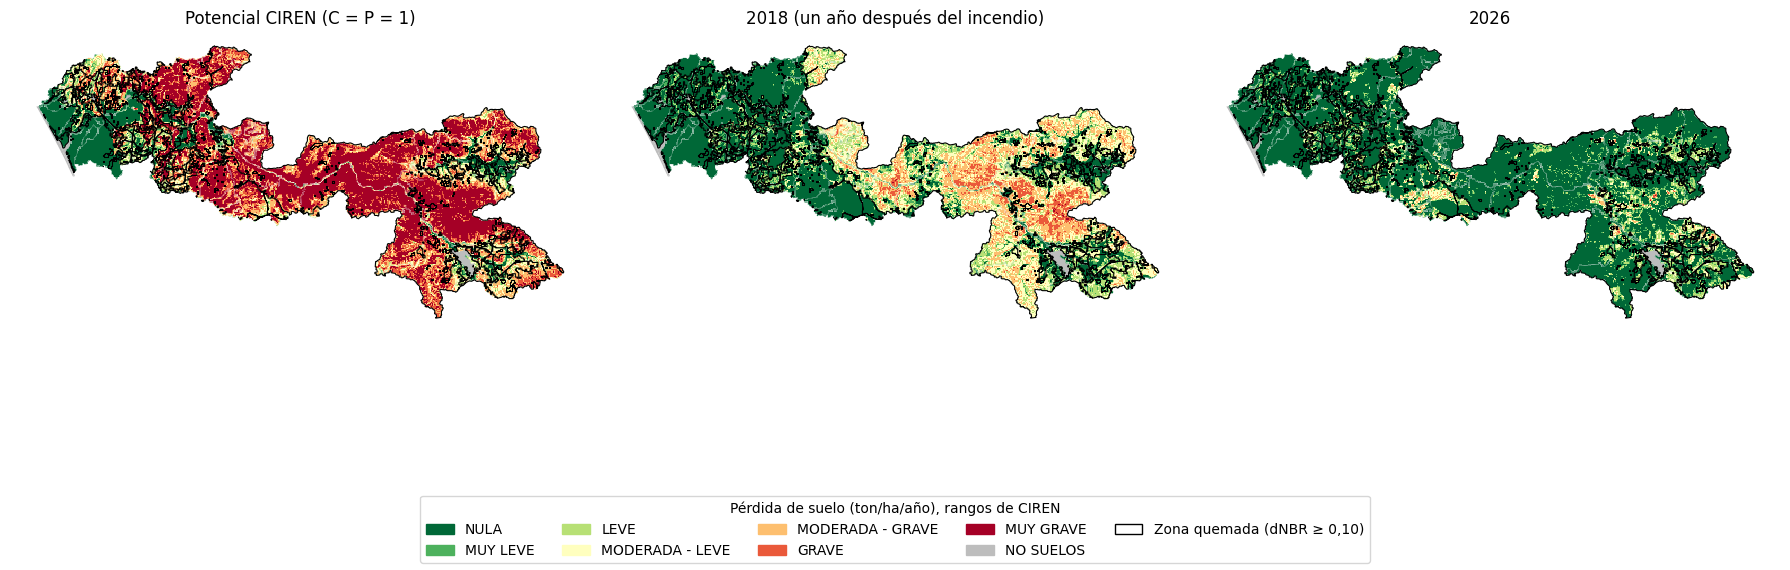

In [19]:
# --- Mapas: potencial, 2018 y 2026 con las clases y colores de CIREN ---
# Mapas de revisión. Los mapas finales (norte, escala gráfica, fuente) se arman en QGIS con el GeoPackage exportado.
color_clase = {c: colores.get(k + 1, "#ffffff") for k, c in enumerate(CLASES)}   # mismos colores del mapa de CIREN (códigos 1 a 7)
borde_quemado = gdf[gdf["ZONA"] == "Quemado"].dissolve()                       # contorno de la zona quemada (dNBR ≥ 0,10)

fig, ejes = plt.subplots(1, 3, figsize=(18, 7))
for ax, (titulo, col) in zip(ejes, [("Potencial CIREN (C = P = 1)", "CLASE_POT"),
                                     ("2018 (un año después del incendio)", "CLASE_2018"),
                                     ("2026", "CLASE_2026")]):
    gdf[~suelo].plot(ax=ax, color=colores[999], linewidth=0)                    # "No suelos" en gris
    datos = gdf[gdf[col].notna()]
    datos.plot(ax=ax, color=datos[col].astype(str).map(color_clase).tolist(), linewidth=0)
    borde_quemado.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ax.set_title(titulo)
    ax.set_axis_off()

leyenda = ([Patch(color=color_clase[c], label=c) for c in CLASES]
           + [Patch(color=colores[999], label="NO SUELOS"),
              Patch(facecolor="none", edgecolor="black", label="Zona quemada (dNBR ≥ 0,10)")])
fig.legend(handles=leyenda, loc="lower center", ncol=5, title="Pérdida de suelo (ton/ha/año), rangos de CIREN")
plt.tight_layout(rect=[0, 0.1, 1, 1])
plt.show()

## 7. Sensibilidad a la lluvia (R de cada año)

En el análisis principal R es fijo (el de CIREN), porque en RUSLE representa un año promedio. Aquí se revisa si la conclusión cambia al considerar la lluvia real de cada año.

$$factor_R = \frac{R_{año}}{R_{promedio}} = \left(\frac{P_{año}}{P_{promedio}}\right)^{1{,}534}$$

Con la fórmula de Bonilla y Vidal (2011), $R = 0{,}028 \cdot P^{1{,}534}$, el coeficiente se cancela en el cociente. De CHIRPS solo se toma **cuánto más o menos llovió ese año respecto de lo normal**, y ese factor se aplica a la potencial de CIREN. El supuesto es que el R de CIREN representa un año promedio.

**Dominio de validez:** la fórmula se ajustó con precipitación media anual; aplicarla a un año suelto la saca de ese dominio. Por eso es un análisis de sensibilidad y no la base del modelo.

In [20]:
# --- Sensibilidad: ¿cambia la conclusión si se considera la lluvia de cada año? ---
def lluvia_media_cuenca(inicio, fin, anios=1):
    p = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
         .filterDate(inicio, fin)
         .select('precipitation')
         .sum()                # mm acumulados en el período
         .divide(anios))       # para el promedio de 30 años: total / 30 = lluvia anual media
    return p.reduceRegion(reducer=ee.Reducer.mean(), geometry=area_de_interes.geometry(),
                          scale=5566,   # resolución nativa de CHIRPS
                          maxPixels=1e9, bestEffort=True).getInfo()['precipitation']

# Si el último año aún no está completo en GEE, la lluvia quedaría subestimada: se revisa antes
dias_2026 = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').filterDate('2025-04-01', '2026-04-01').size().getInfo()
print(f"Días con datos CHIRPS abr-2025 a mar-2026: {dias_2026} de 365")

P_prom = lluvia_media_cuenca('1991-04-01', '2021-04-01', anios=30)   # 30 años hidrológicos (normal climatológica 1991–2020)
P_2018 = lluvia_media_cuenca('2017-04-01', '2018-04-01')             # año hidrológico del primer invierno post-incendio
P_2026 = lluvia_media_cuenca('2025-04-01', '2026-04-01')             # último año hidrológico completo

fR_2018 = (P_2018 / P_prom) ** 1.534     # > 1: año más erosivo que lo normal; < 1: menos erosivo
fR_2026 = (P_2026 / P_prom) ** 1.534
print(f"Lluvia media 1991-2020: {P_prom:.0f} mm | 2017-18: {P_2018:.0f} mm | 2025-26: {P_2026:.0f} mm")
print(f"factor_R 2018 = {fR_2018:.2f} | factor_R 2026 = {fR_2026:.2f}")

# Se repite la Tabla 1 con A ajustado por la lluvia de cada año
sens = analisis.assign(A_2018=analisis["A_2018"] * fR_2018, A_2026=analisis["A_2026"] * fR_2026)
t_sens = resumen(sens, "ZONA")
efecto_R = t_sens.loc["Quemado", "Δ (2018 − 2026)"] - t_sens.loc["No quemado", "Δ (2018 − 2026)"]
print("\nCon R de cada año:")
print(t_sens[["A_2018", "A_2026", "Δ (2018 − 2026)", "Δ %"]].round(3).to_string())
print(f"\nEfecto del incendio con R fijo: {efecto:.2f} | con R de cada año: {efecto_R:.2f} ton/ha/año")
print("La conclusión se mantiene" if np.sign(efecto) == np.sign(efecto_R)
      else "La conclusión CAMBIA al considerar la lluvia: discutirlo en la Etapa 3")

Días con datos CHIRPS abr-2025 a mar-2026: 365 de 365
Lluvia media 1991-2020: 763 mm | 2017-18: 686 mm | 2025-26: 502 mm
factor_R 2018 = 0.85 | factor_R 2026 = 0.53

Con R de cada año:
            A_2018  A_2026  Δ (2018 − 2026)     Δ %
ZONA                                               
No quemado   3.972   3.146            0.826  20.792
Quemado     30.674   2.539           28.136  91.724

Efecto del incendio con R fijo: 32.59 | con R de cada año: 27.31 ton/ha/año
La conclusión se mantiene
